Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteEasyOCR Detected weight: 613142183320228102427116495.601840101417.57.9145
Extracted weight: 613142183320228102427116495.601840101417


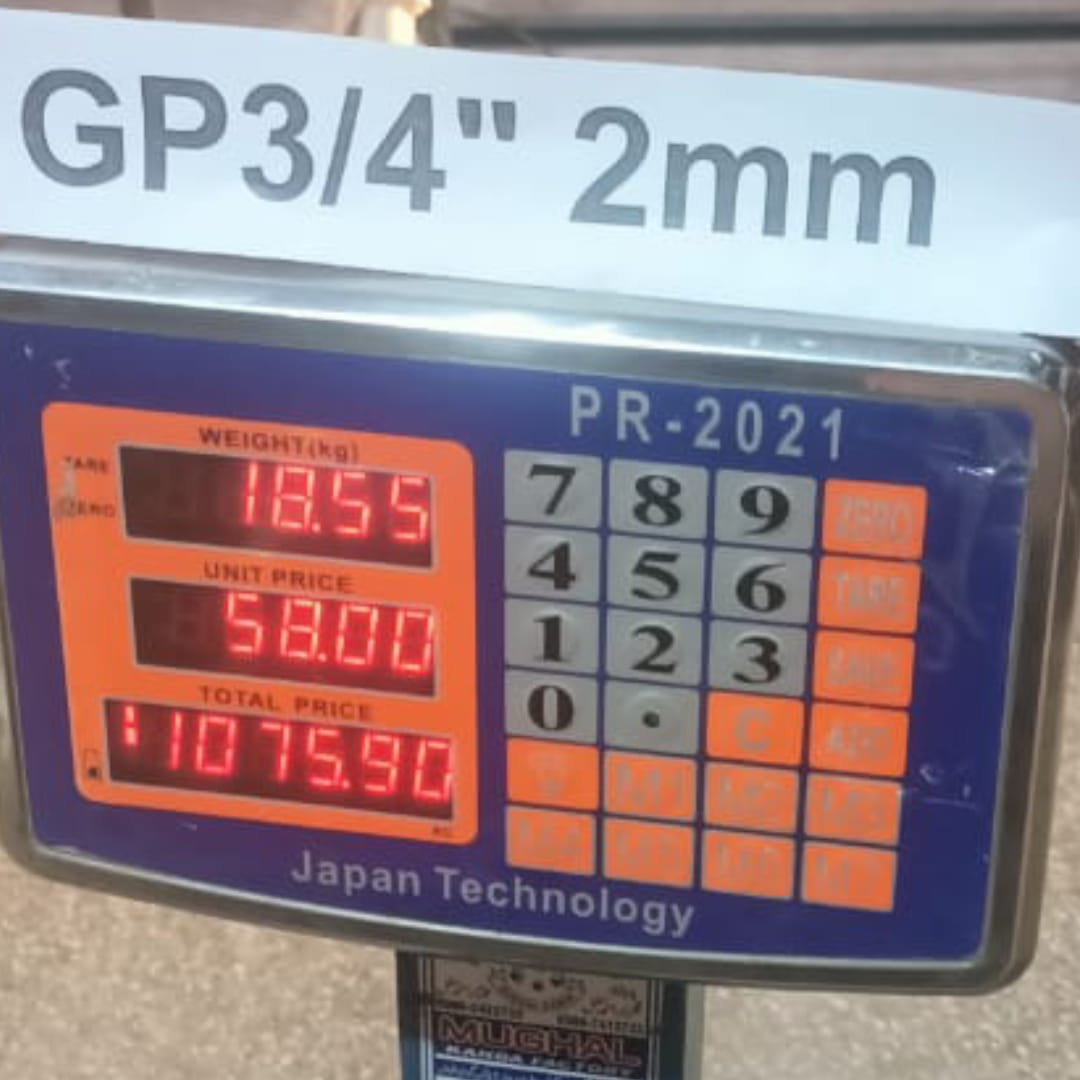

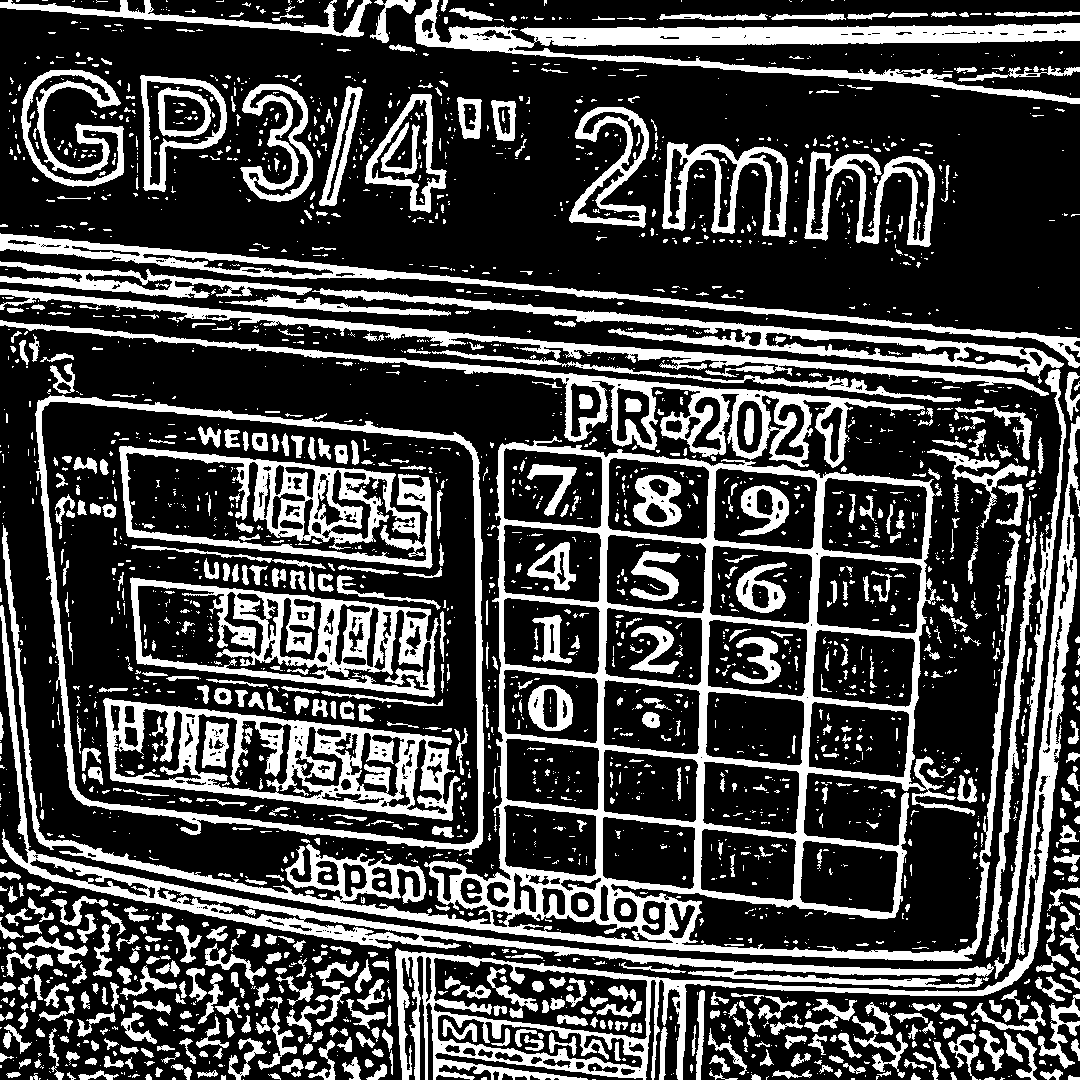

In [6]:
import cv2
import easyocr
import re
from google.colab.patches import cv2_imshow

# --- Step 1: Load image ---
img_path = "WhatsApp Image 2025-10-11 at 10.33.25_5c8c3d5d.jpg"
img = cv2.imread(img_path)
if img is None:
    raise SystemExit("Image not found! Check your file path.")

# --- Step 2: Preprocess full image for OCR ---
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (3,3), 0)
thresh = cv2.adaptiveThreshold(
    blur, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY_INV, 11, 2
)




# --- Step 3: OCR using EasyOCR on full image ---
reader = easyocr.Reader(['en'])
result = reader.readtext(thresh, detail=0, allowlist='0123456789.')  # only digits
easyocr_weight = ''.join(result)
print("EasyOCR Detected weight:", easyocr_weight if easyocr_weight else "None")

# --- Step 4: Extract weight using regex ---
# This regex looks for one or more digits, optionally followed by a period and more digits.
# You might need to adjust this based on the exact format of the weight in your images.
weight_match = re.search(r'\d+\.?\d*', easyocr_weight)
extracted_weight = weight_match.group(0) if weight_match else "Not found"
print("Extracted weight:", extracted_weight)


# --- Step 5: Display full image and processed image ---
cv2_imshow(img)
cv2_imshow(thresh)
cv2.waitKey(0)
cv2.destroyAllWindows()

In [4]:
!pip install easyocr opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 32.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 963.8/963.8 kB 80.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 292.1/292.1 kB 36.7 MB/s eta 0:00:00


ERROR: Could not find a version that satisfies the requirement opencv (from versions: none)
ERROR: No matching distribution found for opencv


OCR result: ['46', '66', '']
Extracted weight: Not found


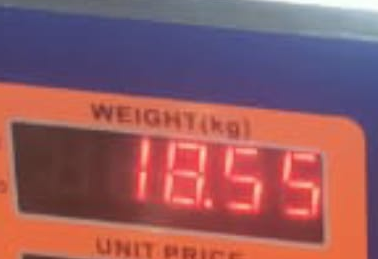

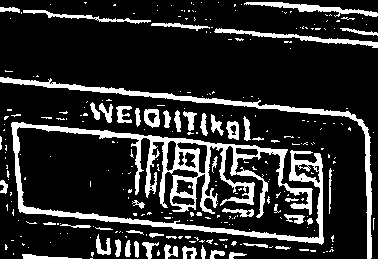

In [14]:
import cv2
import easyocr
import re
from google.colab.patches import cv2_imshow

# --- Step 1: Load image ---
img_path = "WhatsApp Image 2025-10-11 at 10.33.25_5c8c3d5d.jpg"
img = cv2.imread(img_path)
if img is None:
    raise SystemExit("Image not found! Check your file path.")

# --- Step 2: Crop Weight Display Area ---
h, w, _ = img.shape
y1, y2 = int(h * 0.30), int(h * 0.54)
x1, x2 = int(w * 0.1), int(w * 0.45)
roi = img[y1:y2, x1:x2]

# --- Step 3: Preprocess cropped ROI ---
gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (3, 3), 0)
thresh = cv2.adaptiveThreshold(
    blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 11, 2
)

# --- Step 4: OCR using EasyOCR ---
reader = easyocr.Reader(['en'])
result = reader.readtext(thresh, detail=0, allowlist='0123456789.')
print("OCR result:", result)

# --- Step 5: Extract only the weight number ---
easyocr_weight = ''.join(result)
weight_match = re.search(r'\d+\.\d+', easyocr_weight)
extracted_weight = weight_match.group(0) if weight_match else "Not found"

print("Extracted weight:", extracted_weight)

# --- Step 6: Display for debugging ---
cv2_imshow(roi)
cv2_imshow(thresh)
cv2.waitKey(0)
cv2.destroyAllWindows()


All OCR Results:
Text: GP3/4" | Confidence: 0.22
Text: 2m | Confidence: 1.00
Text: PR | Confidence: 1.00
Text: poice | Confidence: 0.11
Text: pue | Confidence: 0.04
Text: # | Confidence: 0.63
Text: 2 | Confidence: 1.00
Text: 472i | Confidence: 0.10
Text: 1157 | Confidence: 0.06
Text: D} | Confidence: 0.37
Text: Q | Confidence: 0.36
Text: WeidiiTIKp) | Confidence: 0.03
Text: Uiut: | Confidence: 0.13
Text: Jotal | Confidence: 0.38
Text: Thioc | Confidence: 0.50
Text: Japa | Confidence: 0.65
Text: Tecknolagy | Confidence: 0.36

Extracted Weight: Not found


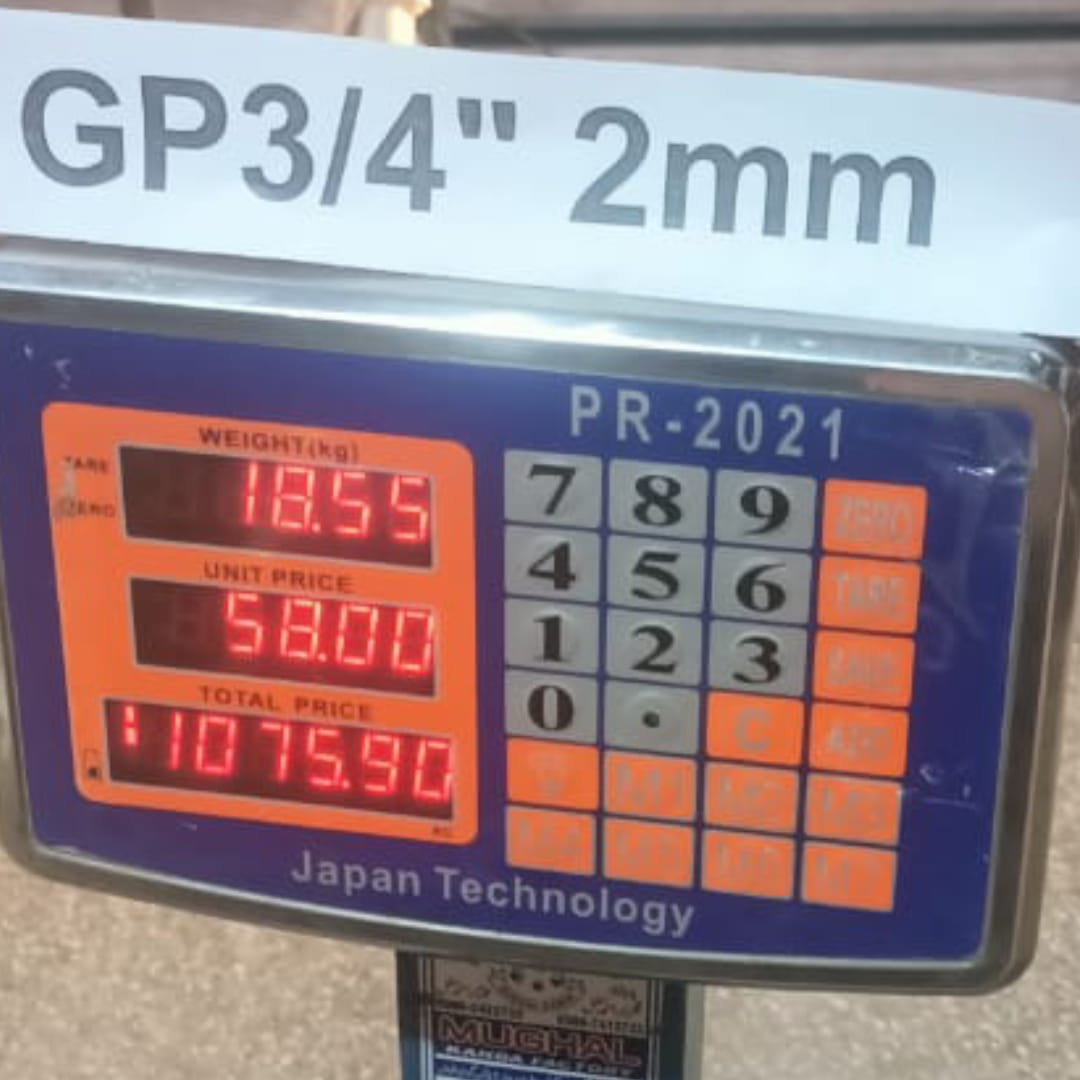

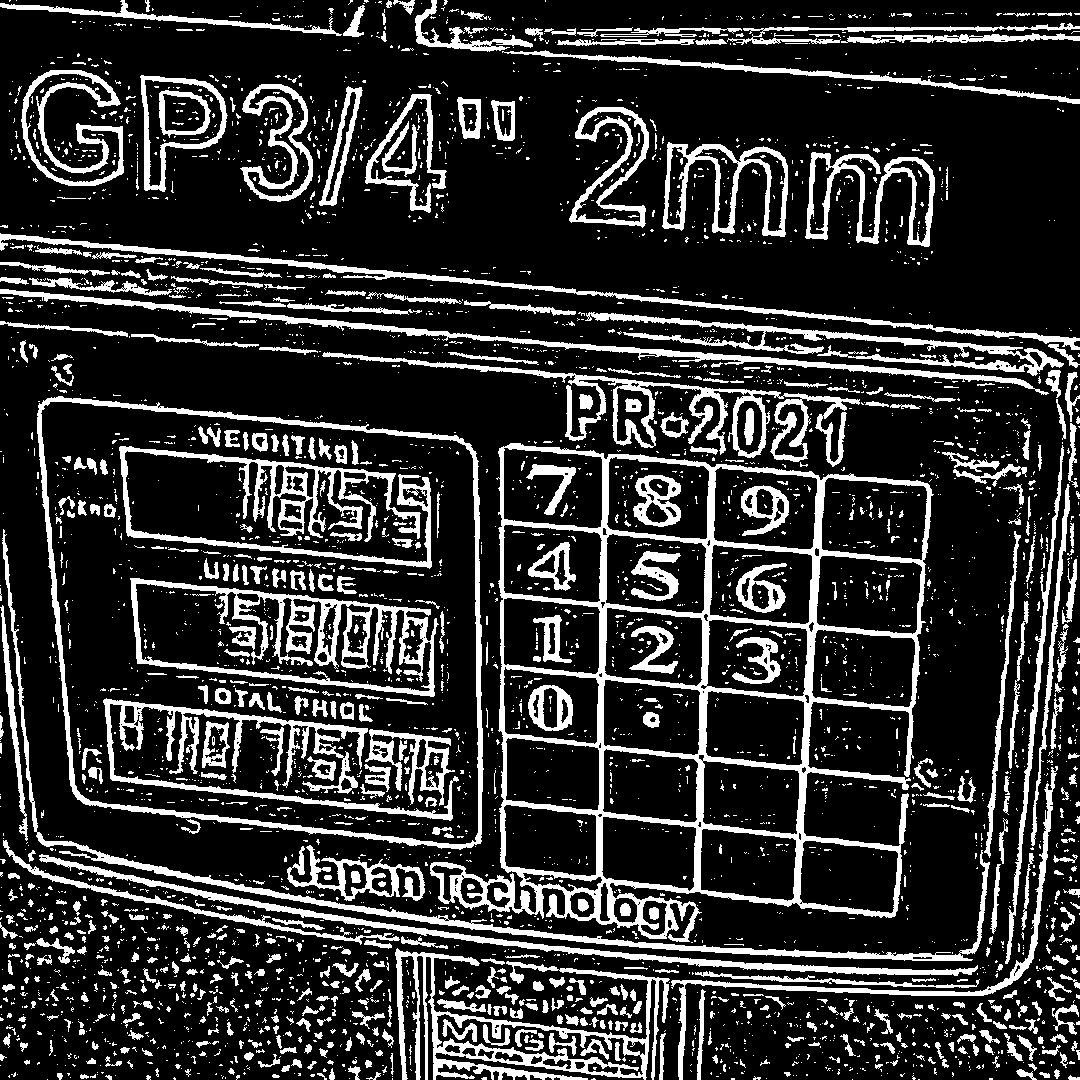

In [15]:
import cv2
import easyocr
import re
from google.colab.patches import cv2_imshow

# --- Step 1: Load full image ---
img_path = "WhatsApp Image 2025-10-11 at 10.33.25_5c8c3d5d.jpg"
img = cv2.imread(img_path)
if img is None:
    raise SystemExit("Image not found! Check your file path.")

# --- Step 2: Preprocess full image ---
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (3, 3), 0)
thresh = cv2.adaptiveThreshold(
    blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 11, 2
)

# --- Step 3: Run EasyOCR on the entire image ---
reader = easyocr.Reader(['en'])
results = reader.readtext(thresh, detail=1)  # detail=1 gives box, text, confidence

# --- Step 4: Print all recognized text ---
print("All OCR Results:")
for (bbox, text, confidence) in results:
    print(f"Text: {text} | Confidence: {confidence:.2f}")

# --- Step 5: Try to detect specific data (like weight, unit, etc.) ---
# Combine all recognized text
all_text = " ".join([text for (_, text, _) in results])

# Find weight (number + optional unit)
weight_match = re.search(r'\d+\.\d+\s?(kg|lb|g)?', all_text.lower())
extracted_weight = weight_match.group(0) if weight_match else "Not found"

print("\nExtracted Weight:", extracted_weight)

# --- Step 6: Display for debugging ---
cv2_imshow(img)
cv2_imshow(thresh)
cv2.waitKey(0)
cv2.destroyAllWindows()

OCR Raw Result: ['001', '1', '01']
Extracted Weight: 001101


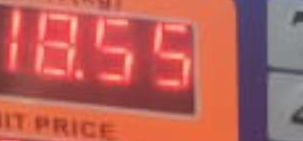

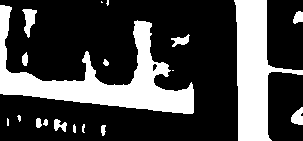

In [27]:
import cv2
import easyocr
import re
from google.colab.patches import cv2_imshow

# --- Step 1: Load image ---
img_path = "WhatsApp Image 2025-10-11 at 10.33.25_5c8c3d5d.jpg"
img = cv2.imread(img_path)
if img is None:
    raise SystemExit("Image not found! Check your file path.")

# --- Step 2: Crop only the digital display area (adjust coordinates as needed) ---
h, w, _ = img.shape
# These ratios work for most scale displays; adjust by testing
y1, y2 = int(h * 0.42), int(h * 0.55)
x1, x2 = int(w * 0.22), int(w * 0.50)
display = img[y1:y2, x1:x2]

# --- Step 3: Preprocess for 7-segment clarity ---
gray = cv2.cvtColor(display, cv2.COLOR_BGR2GRAY)

# 1️⃣ Enhance contrast
gray = cv2.convertScaleAbs(gray, alpha=2.0, beta=0)

# 2️⃣ Remove glare and smooth noise
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# 3️⃣ Invert if background is dark
_, binary = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# --- Step 4: Run EasyOCR ---
reader = easyocr.Reader(['en'])
results = reader.readtext(binary, detail=0, allowlist='0123456789.')

print("OCR Raw Result:", results)

# --- Step 5: Extract numeric weight ---
combined = "".join(results)
weight_match = re.search(r'\d*\.?\d*', combined)
extracted_weight = weight_match.group(0) if weight_match else "Not found"
print("Extracted Weight:", extracted_weight)

# --- Step 6: Visualize ---
cv2_imshow(display)
cv2_imshow(binary)
cv2.waitKey(0)
cv2.destroyAllWindows()


Detected Weight: 45551071.0


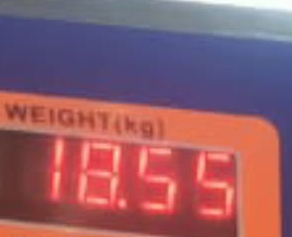

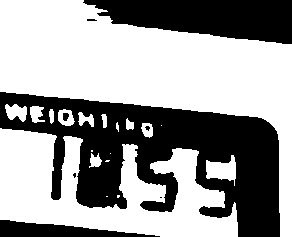

In [33]:
import cv2
import easyocr
import numpy as np
import re
from google.colab.patches import cv2_imshow

# --- Step 1: Load image ---
img_path = "WhatsApp Image 2025-10-11 at 10.33.25_5c8c3d5d.jpg"
img = cv2.imread(img_path)
if img is None:
    raise SystemExit("Image not found!")

# --- Step 2: Crop only weight area ---
# (Tune these crop values based on your scale position)
h, w, _ = img.shape
y1, y2 = int(h*0.3), int(h*0.52)
x1, x2 = int(w*0.18), int(w*0.45)
roi = img[y1:y2, x1:x2]

# --- Step 3: Preprocess for OCR ---
gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
gray = cv2.GaussianBlur(gray, (3, 3), 0)
gray = cv2.bitwise_not(gray)  # Invert colors (dark digits on bright background)
_, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# --- Step 4: Read using EasyOCR ---
reader = easyocr.Reader(['en'])
result = reader.readtext(thresh, detail=0, allowlist='0123456789.')

# Combine OCR results
text = ''.join(result)
match = re.search(r'\d+\.\d+', text)
weight = match.group(0) if match else "Not found"

print("Detected Weight:", weight)

cv2_imshow( roi)
cv2_imshow( thresh)
cv2.waitKey(0)
cv2.destroyAllWindows()


Detected Weight: Not found


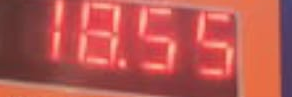

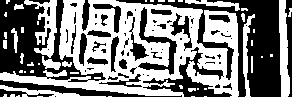

In [44]:
import cv2
import easyocr
import numpy as np
import re
from google.colab.patches import cv2_imshow

# -----------------------------
# Step 1: Load Image
# -----------------------------
img_path = "WhatsApp Image 2025-10-11 at 10.33.25_5c8c3d5d.jpg"
img = cv2.imread(img_path)
if img is None:
    raise SystemExit("Image not found!")

# -----------------------------
# Step 2: Crop the weight display area
# -----------------------------
# Adjust these coordinates based on your scale
h, w, _ = img.shape
y1, y2 = int(h*0.43), int(h*0.52)
x1, x2 = int(w*0.18), int(w*0.45)
roi = img[y1:y2, x1:x2]

# -----------------------------
# Step 3: Preprocess for OCR
# -----------------------------
gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
# Adaptive threshold for variable lighting
thresh = cv2.adaptiveThreshold(
    gray, 255, cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY_INV, 11, 2
)
# Optional: dilate to connect broken digit parts
kernel = np.ones((2, 2), np.uint8)
thresh = cv2.dilate(thresh, kernel, iterations=1)

# -----------------------------
# Step 4: Read using EasyOCR
# -----------------------------
reader = easyocr.Reader(['en'])
results = reader.readtext(thresh)

# -----------------------------
# Step 5: Filter and combine digits
# -----------------------------
# Use only text with high probability and allowed characters
ocr_texts = []
for (bbox, text, prob) in results:
    # Keep only numbers and dot
    text_clean = re.sub(r'[^0-9.]', '', text)
    if len(text_clean) > 0 and prob > 0.4:  # threshold probability
        ocr_texts.append(text_clean)

# Combine all parts
combined_text = ''.join(ocr_texts)

# Extract weight using regex (numbers with decimal point)
matches = re.findall(r'\d+\.\d+', combined_text)
weight = matches[0] if matches else "Not found"

# -----------------------------
# Step 6: Show results
# -----------------------------
print("Detected Weight:", weight)

cv2_imshow(roi)
cv2_imshow(thresh)

cv2.waitKey(0)
cv2.destroyAllWindows()


In [3]:
import cv2
import numpy as np

# Load image
img_path = "WhatsApp Image 2025-10-11 at 10.33.25_5c8c3d5d.jpg"
img = cv2.imread(img_path)
if img is None:
    raise SystemExit("Image not found!")

# Crop the weight display area
h, w, _ = img.shape
y1, y2 = int(h*0.43), int(h*0.52)
x1, x2 = int(w*0.18), int(w*0.45)
roi = img[y1:y2, x1:x2]

# Convert to grayscale before threshold
roi_gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)

# Threshold with Otsu
_, thresh = cv2.threshold(roi_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Find contours of each digit
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
digits = []
for cnt in contours:
    x, y, w, h = cv2.boundingRect(cnt)
    if h > 20 and w > 10:  # filter noise
        digit_roi = thresh[y:y+h, x:x+w]
        digits.append((x, digit_roi))

# Sort digits left-to-right
digits = sorted(digits, key=lambda x: x[0])

# Now each digit_roi can be passed to your 7-segment detect_digit function
# Example:
# weight_digits = [detect_digit(digit_roi) for _, digit_roi in digits]
# weight = "".join(weight_digits)



In [5]:
import cv2
import numpy as np

# -------------------------------
# 1. Load the image
# -------------------------------
img_path = r"WhatsApp Image 2025-10-11 at 10.33.25_5c8c3d5d.jpg"
img = cv2.imread(img_path)
if img is None:
    raise SystemExit("Image not found!")

# -------------------------------
# 2. Crop the display area manually (adjust as needed)
# -------------------------------
h, w, _ = img.shape
y1, y2 = int(h*0.43), int(h*0.52)
x1, x2 = int(w*0.18), int(w*0.45)
roi = img[y1:y2, x1:x2]

# -------------------------------
# 3. Grayscale and threshold
# -------------------------------
gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY)
_, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3,3))
thresh = cv2.morphologyEx(thresh, cv2.MORPH_CLOSE, kernel)

# -------------------------------
# 4. Find contours of digits
# -------------------------------
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
digit_boxes = [cv2.boundingRect(c) for c in contours]
# Filter noise
digit_boxes = [b for b in digit_boxes if b[2] > 10 and b[3] > 20]
# Sort left to right
digit_boxes = sorted(digit_boxes, key=lambda b: b[0])

# -------------------------------
# 5. 7-segment mapping
# -------------------------------
DIGITS_LOOKUP = {
    (1,1,1,1,1,1,0): '0',
    (0,1,1,0,0,0,0): '1',
    (1,1,0,1,1,0,1): '2',
    (1,1,1,1,0,0,1): '3',
    (0,1,1,0,0,1,1): '4',
    (1,0,1,1,0,1,1): '5',
    (1,0,1,1,1,1,1): '6',
    (1,1,1,0,0,0,0): '7',
    (1,1,1,1,1,1,1): '8',
    (1,1,1,1,0,1,1): '9'
}

# -------------------------------
# 6. Detect each digit
# -------------------------------
def detect_digit(roi):
    h, w = roi.shape
    segments = [
        ((int(0.15*w), 0), (int(0.85*w), int(0.15*h))),  # top
        ((int(0.85*w), int(0.15*h)), (w, int(0.5*h))),   # top-right
        ((int(0.85*w), int(0.5*h)), (w, int(0.85*h))),   # bottom-right
        ((int(0.15*w), int(0.85*h)), (int(0.85*w), h)),  # bottom
        ((0, int(0.5*h)), (int(0.15*w), int(0.85*h))),   # bottom-left
        ((0, int(0.15*h)), (int(0.15*w), int(0.5*h))),   # top-left
        ((int(0.15*w), int(0.425*h)), (int(0.85*w), int(0.575*h)))  # middle
    ]

    on_off = []
    for (x1,y1),(x2,y2) in segments:
        if x2 - x1 <= 0 or y2 - y1 <= 0:
            on_off.append(0)
            continue
        seg_roi = roi[y1:y2, x1:x2]
        total = cv2.countNonZero(seg_roi)
        area = (x2 - x1)*(y2 - y1)
        if area == 0:
            on_off.append(0)
        elif total / float(area) > 0.5:
            on_off.append(1)
        else:
            on_off.append(0)
    return DIGITS_LOOKUP.get(tuple(on_off), '?')

# -------------------------------
# 7. Detect decimal point
# -------------------------------
def is_decimal_point(box):
    x, y, w, h = box
    return 2 < w < h/3

# -------------------------------
# 8. Process all digits
# -------------------------------
detected_digits = []

for x, y, w, h in digit_boxes:
    roi_digit = thresh[y:y+h, x:x+w]
    if is_decimal_point((x,y,w,h)):
        detected_digits.append('.')
    else:
        detected_digits.append(detect_digit(roi_digit))

# -------------------------------
# 9. Combine and display
# -------------------------------
weight = ''.join(detected_digits)
print("Detected weight:", weight)

# -------------------------------
# 10. Optional visualization
# -------------------------------
for x, y, w, h in digit_boxes:
    cv2.rectangle(roi, (x,y), (x+w, y+h), (0,255,0), 2)

cv2.imshow("LED Display Cropped", roi)
cv2.imshow("Thresholded", thresh)
cv2.waitKey(0)
cv2.destroyAllWindows()


Detected weight: ?.


DisabledFunctionError: cv2.imshow() is disabled in Colab, because it causes Jupyter sessions
to crash; see https://github.com/jupyter/notebook/issues/3935.
As a substitution, consider using
  from google.colab.patches import cv2_imshow
